In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

# Two-Burn Orbit Raise

This example demonstrates the use of a Trajectory to encapsulate a
three-phase orbit raising maneuver with a burn-coast-burn phase
sequence. This example is based on the problem provided in
Enright {cite}`enright1991optimal`.

The dynamics are given by

\begin{align}
  \frac{dr}{dt} &= v_r \\
  \frac{d\theta}{dt} &= \frac{v_\theta}{r} \\
  \frac{dv_r}{dt} &= \frac{v^2_\theta}{r} - \frac{1}{r^2} + a_{thrust} \sin u_1 \\
  \frac{dv_\theta}{dt} &= - \frac{v_r v_\theta}{r} + a_{thrust} \cos u_1 \\
  \frac{da_{thrust}}{dt} &= \frac{a^2_{thrust}}{c} \\
  \frac{d \Delta v}{dt} &= a_{thrust}
\end{align}

The initial conditions are

\begin{align}
  r &= 1 \rm{\,DU} \\
  \theta &= 0 \rm{\,rad} \\
  v_r &= 0 \rm{\,DU/TU}\\
  v_\theta &= 1 \rm{\,DU/TU}\\
  a_{thrust} &= 0.1 \rm{\,DU/TU^2}\\
  \Delta v &= 0 \rm{\,DU/TU}
\end{align}

and the final conditions are

\begin{align}
  r &= 3 \rm{\,DU} \\
  \theta &= \rm{free} \\
  v_r &= 0 \rm{\,DU/TU}\\
  v_\theta &= \sqrt{\frac{1}{3}} \rm{\,DU/TU}\\
  a_{thrust} &= \rm{free}\\
  \Delta v &= \rm{free}
\end{align}

## Building and running the problem

The following code instantiates our problem, our trajectory, three
phases, and links them accordingly. The spacecraft initial position,
velocity, and acceleration magnitude are fixed. The objective is to
minimize the delta-V needed to raise the spacecraft into a circular
orbit at 3 Earth radii.

Note the call to _link\_phases_ which provides time,
position, velocity, and delta-V continuity across all phases, and
acceleration continuity between the first and second burn phases.
Acceleration is 0 during the coast phase. Alternatively, we could have
specified a different ODE for the coast phase, as in the example.

This example runs inconsistently with SLSQP but is solved handily by
IPOPT and SNOPT.

In [2]:
import openmdao.api as om
om.display_source("dymos.examples.finite_burn_orbit_raise.finite_burn_eom")

import numpy as np
import openmdao.api as om
import openmdao.utils.units as units

# Add canonical units to OpenMDAO
MU_earth = 3.986592936294783e14
R_earth = 6378137.0

period = 2 * np.pi * np.sqrt(R_earth**3 / MU_earth)

# Add canonical time and distance units for these EOM
units.add_unit('TU', '{0}*s'.format(period))
units.add_unit('DU', '{0}*m'.format(R_earth))


class FiniteBurnODE(om.ExplicitComponent):

    def initialize(self):
        self.options.declare('num_nodes', types=int)

    def setup(self):
        nn = self.options['num_nodes']

        # Inputs
        self.add_input('r',
                       val=np.ones(nn),
                       desc='radius from center of attraction',
                       units='DU')

        self.add_input('theta',
                       val=np.zeros(nn),
                       desc='anomaly term',
                       units='rad')

        self.add_input('vr',
                       val=np.zeros(nn),
                       desc='local vertical velocity component',
                       units='DU/TU')

        self.add_input('vt',
                       val=np.zeros(nn),
                       desc='local horizontal velocity component',
                       units='DU/TU')

        self.add_input('accel',
                       val=np.zeros(nn),
                       desc='acceleration due to thrust',
                       units='DU/TU**2')

        self.add_input('u1',
                       val=np.zeros(nn),
                       desc='thrust angle above local horizontal',
                       units='rad')

        self.add_input('c',
                       val=np.zeros(nn),
                       desc='exhaust velocity',
                       units='DU/TU')

        self.add_output('r_dot',
                        val=np.ones(nn),
                        desc='rate of change of radius from center of attraction',
                        units='DU/TU')

        self.add_output('theta_dot',
                        val=np.zeros(nn),
                        desc='rate of change of anomaly term',
                        units='rad/TU')

        self.add_output('vr_dot',
                        val=np.zeros(nn),
                        desc='rate of change of local vertical velocity component',
                        units='DU/TU**2')

        self.add_output('vt_dot',
                        val=np.zeros(nn),
                        desc='rate of change of local horizontal velocity component',
                        units='DU/TU**2')

        self.add_output('at_dot',
                        val=np.zeros(nn),
                        desc='rate of change of acceleration due to thrust',
                        units='DU/TU**3')

        self.add_output('deltav_dot',
                        val=np.zeros(nn),
                        desc='rate of change of delta-V',
                        units='DU/TU**2')

        self.add_output('pos_x',
                        val=np.zeros(nn),
                        desc='x-component of position',
                        units='DU')

        self.add_output('pos_y',
                        val=np.zeros(nn),
                        desc='x-component of position',
                        units='DU')

        # Setup partials
        ar = np.arange(self.options['num_nodes'])

        # r dot is a linear function of vr, so provide the partial value here
        self.declare_partials(of='r_dot', wrt='vr', rows=ar, cols=ar, val=1.0)

        self.declare_partials(of='theta_dot', wrt='r', rows=ar, cols=ar)
        self.declare_partials(of='theta_dot', wrt='vt', rows=ar, cols=ar)

        self.declare_partials(of='vr_dot', wrt='r', rows=ar, cols=ar)
        self.declare_partials(of='vr_dot', wrt='vt', rows=ar, cols=ar)
        self.declare_partials(of='vr_dot', wrt='accel', rows=ar, cols=ar)
        self.declare_partials(of='vr_dot', wrt='u1', rows=ar, cols=ar)

        self.declare_partials(of='vt_dot', wrt='r', rows=ar, cols=ar)
        self.

In [3]:
%matplotlib inline

In [4]:
import numpy as np
import openmdao.api as om
import dymos as dm
import matplotlib.pyplot as plt
from dymos.examples.finite_burn_orbit_raise.finite_burn_eom import FiniteBurnODE

p = om.Problem(model=om.Group())

p.driver = om.pyOptSparseDriver()
p.driver.options['optimizer'] = 'IPOPT'
p.driver.declare_coloring()

traj = dm.Trajectory()

traj.add_parameter('c', opt=False, val=1.5, units='DU/TU',
                   targets={'burn1': ['c'], 'coast': ['c'], 'burn2': ['c']})

# First Phase (burn)

burn1 = dm.Phase(ode_class=FiniteBurnODE,
                 transcription=dm.GaussLobatto(num_segments=5, order=3, compressed=False))

burn1 = traj.add_phase('burn1', burn1)

burn1.set_time_options(fix_initial=True, duration_bounds=(.5, 10), units='TU')
burn1.add_state('r', fix_initial=True, fix_final=False, defect_scaler=100.0,
                rate_source='r_dot', units='DU')
burn1.add_state('theta', fix_initial=True, fix_final=False, defect_scaler=100.0,
                rate_source='theta_dot', units='rad')
burn1.add_state('vr', fix_initial=True, fix_final=False, defect_scaler=100.0,
                rate_source='vr_dot', units='DU/TU')
burn1.add_state('vt', fix_initial=True, fix_final=False, defect_scaler=100.0,
                rate_source='vt_dot', units='DU/TU')
burn1.add_state('accel', fix_initial=True, fix_final=False,
                rate_source='at_dot', units='DU/TU**2')
burn1.add_state('deltav', fix_initial=True, fix_final=False,
                rate_source='deltav_dot', units='DU/TU')
burn1.add_control('u1', rate_continuity=True, rate2_continuity=True, units='deg',
                  scaler=0.01, rate_continuity_scaler=0.001, rate2_continuity_scaler=0.001,
                  lower=-30, upper=30)
# Second Phase (Coast)
coast = dm.Phase(ode_class=FiniteBurnODE,
                 transcription=dm.GaussLobatto(num_segments=5, order=3, compressed=False))

coast.set_time_options(initial_bounds=(0.5, 20), duration_bounds=(.5, 50), duration_ref=50,
                       units='TU')
coast.add_state('r', fix_initial=False, fix_final=False, defect_scaler=100.0,
                rate_source='r_dot', targets=['r'], units='DU')
coast.add_state('theta', fix_initial=False, fix_final=False, defect_scaler=100.0,
                rate_source='theta_dot', targets=['theta'], units='rad')
coast.add_state('vr', fix_initial=False, fix_final=False, defect_scaler=100.0,
                rate_source='vr_dot', targets=['vr'], units='DU/TU')
coast.add_state('vt', fix_initial=False, fix_final=False, defect_scaler=100.0,
                rate_source='vt_dot', targets=['vt'], units='DU/TU')
coast.add_state('accel', fix_initial=True, fix_final=True,
                rate_source='at_dot', targets=['accel'], units='DU/TU**2')
coast.add_state('deltav', fix_initial=False, fix_final=False,
                rate_source='deltav_dot', units='DU/TU')

coast.add_parameter('u1', opt=False, val=0.0, units='deg', targets=['u1'])

# Third Phase (burn)
burn2 = dm.Phase(ode_class=FiniteBurnODE,
                 transcription=dm.GaussLobatto(num_segments=5, order=3, compressed=False))

traj.add_phase('coast', coast)
traj.add_phase('burn2', burn2)

burn2.set_time_options(initial_bounds=(0.5, 50), duration_bounds=(.5, 10), initial_ref=10,
                       units='TU')
burn2.add_state('r', fix_initial=False, fix_final=True, defect_scaler=100.0,
                rate_source='r_dot', units='DU')
burn2.add_state('theta', fix_initial=False, fix_final=False, defect_scaler=100.0,
                rate_source='theta_dot', units='rad')
burn2.add_state('vr', fix_initial=False, fix_final=True, defect_scaler=1000.0,
                rate_source='vr_dot', units='DU/TU')
burn2.add_state('vt', fix_initial=False, fix_final=True, defect_scaler=1000.0,
                rate_source='vt_dot', units='DU/TU')
burn2.add_state('accel', fix_initial=False, fix_final=False, defect_scaler=1.0,
                rate_source='at_dot', units='DU/TU**2')
burn2.add_state('deltav', fix_initial=False, fix_final=False, defect_scaler=1.0,
                rate_source='deltav_dot', units='DU/TU')

burn2.add_objective('deltav', loc='final', scaler=100.0)

burn2.add_control('u1', rate_continuity=True, rate2_continuity=True, units='deg',
                  scaler=0.01, lower=-90, upper=90)

burn1.add_timeseries_output('pos_x')
coast.add_timeseries_output('pos_x')
burn2.add_timeseries_output('pos_x')

burn1.add_timeseries_output('pos_y')
coast.add_timeseries_output('pos_y')
burn2.add_timeseries_output('pos_y')

# Link Phases
traj.link_phases(phases=['burn1', 'coast', 'burn2'],
                 vars=['time', 'r', 'theta', 'vr', 'vt', 'deltav'])

traj.link_phases(phases=['burn1', 'burn2'], vars=['accel'])

p.model.add_subsystem('traj', subsys=traj)

# Finish Problem Setup

p.setup(check=True)

# Set Initial Guesses
p.set_val('traj.parameters:c', val=1.5, units='DU/TU')

burn1 = p.model.traj.phases.burn1
burn2 = p.model.traj.phases.burn2
coast = p.model.traj.phases.coast

burn1.set_time_val(initial=0.0, duration=2.25)
burn1.set_state_val('r', [1, 1.5])
burn1.set_state_val('theta', [0, 1.7])
burn1.set_state_val('vr', [0, 0])
burn1.set_state_val('vt', [1, 1])
burn1.set_state_val('accel', [0.1, 0.0])
burn1.set_state_val('deltav', [0, 0.1])
burn1.set_control_val('u1', [-3.5, 13.0])

coast.set_time_val(initial=2.25, duration=3.0)
coast.set_state_val('r', [1.3, 1.5])
coast.set_state_val('theta', [2.1767, 1.7])
coast.set_state_val('vr', [0.3285, 0])
coast.set_state_val('vt', [0.97, 1])
coast.set_state_val('accel', [0, 0])

burn2.set_time_val(initial=5.25, duration=1.75)
burn2.set_state_val('r', [1, 3])
burn2.set_state_val('theta', [0, 4])
burn2.set_state_val('vr', [0, 0])
burn2.set_state_val('vt', [1, np.sqrt(1 / 3)])
burn2.set_state_val('accel', [0.1, 0.0])
burn2.set_state_val('deltav', [0.1, 0.2])
burn2.set_control_val('u1', [0, 0])

dm.run_problem(p, simulate=True)

INFO: checking out_of_order...


INFO:     out_of_order check complete (0.001542 sec).


INFO: checking system...


INFO:     system check complete (0.000039 sec).


INFO: checking solvers...


...


Jacobian shape: (112, 204)  (3.64% nonzero)
FWD solves: 13   REV solves: 0
Total colors vs. total size: 13 vs 204  (93.63% improvement)

Sparsity computed using tolerance: 1e-25.
Dense total jacobian for Problem 'finite_burn_orbit_raise' was computed 3 times.
Time to compute sparsity:   0.7573 sec
Time to compute coloring:   0.2281 sec
Memory to compute coloring:   0.5000 MB
Coloring created on: 2026-10-30 15:44:17




Optimization Problem -- Optimization using pyOpt_sparse
    Objective Function: _objfunc

    Solution: 
--------------------------------------------------------------------------------
    Total Time:                    4.2810
       User Objective Time :       0.2061
       User Sensitivity Time :     2.3213
       Interface Time :            0.2034
       Opt Solver Time:            1.5502
    Calls to Objective Function :      28
    Calls to Sens Function :           28


   Objectives
      Index  Name                                Value
          0  traj.burn2.states:deltav     3.989839E+01

   Variables (c - continuous, i - integer, d - discrete)
      Index  Name                         Type      Lower Bound            Value      Upper Bound     Status
          0  traj.burn1.t_duration_0         c     5.000000E-01     2.228030E+00     1.000000E+01           
          1  traj.burn1.states:r_0           c    -1.000000E+20     1.002411E+00     1.000000E+20           
       


Simulating trajectory traj


Done simulating trajectory traj


Problem: finite_burn_orbit_raise
Driver:  pyOptSparseDriver
  success     : True
  iterations  : 30
  runtime     : 5.5721E+00 s
  model_evals : 30
  model_time  : 1.6360E-01 s
  deriv_evals : 29
  deriv_time  : 2.2787E+00 s
  exit_status : SUCCESS

## Plotting the results

The following code cell reads the resulting state, time, and control histories from the solution and simulation record files and plots them. It is collapsed by default but can be viewed by expanding it with the button to the right.

<>:25: SyntaxWarning: invalid escape sequence '\D'
<>:25: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_7467/2573435747.py:25: SyntaxWarning: invalid escape sequence '\D'
  ax_deltav.set_ylabel('${\Delta}v$ ($DU/TU$)')


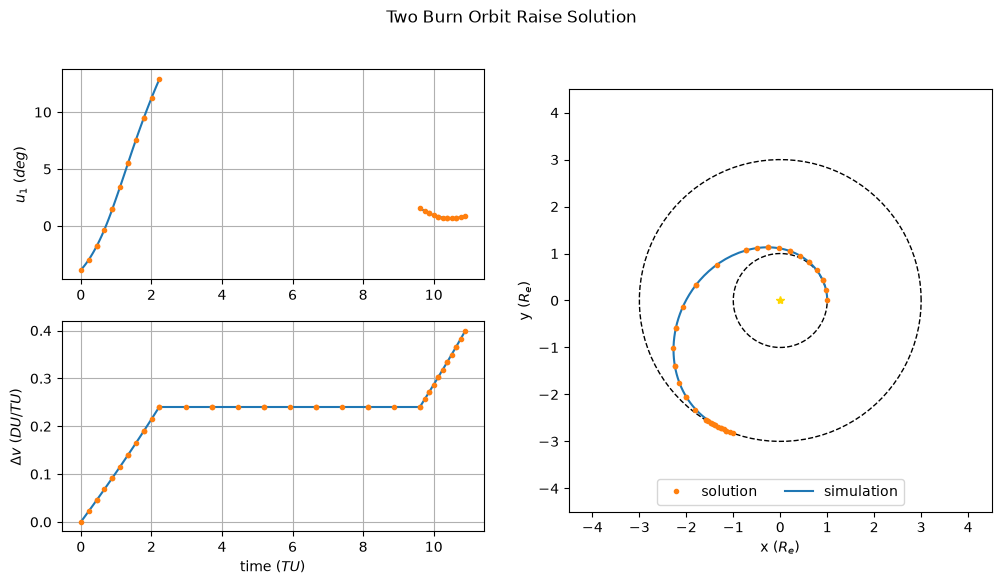

In [5]:
sol = om.CaseReader(p.get_outputs_dir() / 'dymos_solution.db').get_case('final')
sim = om.CaseReader(traj.sim_prob.get_outputs_dir() / 'dymos_simulation.db').get_case('final')

fig = plt.figure(figsize=(12, 6))
fig.suptitle('Two Burn Orbit Raise Solution')
ax_u1 = plt.subplot2grid((2, 2), (0, 0))
ax_deltav = plt.subplot2grid((2, 2), (1, 0))
ax_xy = plt.subplot2grid((2, 2), (0, 1), rowspan=2)

span = np.linspace(0, 2 * np.pi, 100)
ax_xy.plot(np.cos(span), np.sin(span), 'k--', lw=1)
ax_xy.plot(3 * np.cos(span), 3 * np.sin(span), 'k--', lw=1)
ax_xy.set_xlim(-4.5, 4.5)
ax_xy.set_ylim(-4.5, 4.5)

ax_xy.set_xlabel('x ($R_e$)')
ax_xy.set_ylabel('y ($R_e$)')
ax_xy.set_aspect('equal')
ax_xy.plot([0], [0], '*', color='gold')

ax_u1.set_ylabel('$u_1$ ($deg$)')
ax_u1.grid(True)

ax_deltav.set_xlabel('time ($TU$)')
ax_deltav.set_ylabel('${\Delta}v$ ($DU/TU$)')
ax_deltav.grid(True)

t_sol = dict((phs, sol.get_val(f'traj.{phs}.timeseries.time'.format(phs)))
             for phs in ['burn1', 'coast', 'burn2'])
x_sol = dict((phs, sol.get_val(f'traj.{phs}.timeseries.pos_x'.format(phs)))
             for phs in ['burn1', 'coast', 'burn2'])
y_sol = dict((phs, sol.get_val(f'traj.{phs}.timeseries.pos_y'.format(phs)))
             for phs in ['burn1', 'coast', 'burn2'])
dv_sol = dict((phs, sol.get_val(f'traj.{phs}.timeseries.deltav'.format(phs)))
              for phs in ['burn1', 'coast', 'burn2'])
u1_sol = dict((phs, sol.get_val(f'traj.{phs}.timeseries.u1'.format(phs), units='deg'))
              for phs in ['burn1', 'burn2'])

t_exp = dict((phs, sim.get_val(f'traj.{phs}.timeseries.time'))
             for phs in ['burn1', 'coast', 'burn2'])
x_exp = dict((phs, sim.get_val(f'traj.{phs}.timeseries.pos_x'))
             for phs in ['burn1', 'coast', 'burn2'])
y_exp = dict((phs, sim.get_val(f'traj.{phs}.timeseries.pos_y'))
             for phs in ['burn1', 'coast', 'burn2'])
dv_exp = dict((phs, sim.get_val(f'traj.{phs}.timeseries.deltav'))
              for phs in ['burn1', 'coast', 'burn2'])
u1_exp = dict((phs, sim.get_val(f'traj.{phs}.timeseries.u1',
                                units='deg'))
              for phs in ['burn1', 'burn2'])

for phs in ['burn1', 'coast', 'burn2']:
    try:
        ax_u1.plot(t_exp[phs], u1_exp[phs], '-', marker=None, color='C0')
        ax_u1.plot(t_sol[phs], u1_sol[phs], 'o', mfc='C1', mec='C1', ms=3)
    except KeyError:
        pass

    ax_deltav.plot(t_exp[phs], dv_exp[phs], '-', marker=None, color='C0')
    ax_deltav.plot(t_sol[phs], dv_sol[phs], 'o', mfc='C1', mec='C1', ms=3)

    exp_plt, = ax_xy.plot(x_exp[phs], y_exp[phs], '-', marker=None, color='C0', label='explicit')
    imp_plt, = ax_xy.plot(x_sol[phs], y_sol[phs], 'o', mfc='C1', mec='C1', ms=3, label='implicit')

    
ax_xy.legend(handles=[imp_plt, exp_plt], labels=['solution', 'simulation'], loc='lower center', ncol=2)
    
plt.show()

In [6]:
from openmdao.utils.assert_utils import assert_near_equal

assert_near_equal(p.get_val('traj.burn2.states:deltav')[-1], 0.3995,
                  tolerance=2.0E-3)

np.float64(0.0012918110463770996)

## References

```{bibliography}
:filter: docname in docnames
```